# 02 - Contrôle des marts

Vérifications des tables du schéma `marts` après `dbt build`.

In [1]:
import os

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine

load_dotenv("../.env")

engine = create_engine(
    URL.create(
        "postgresql+psycopg2",
        username=os.environ["WAREHOUSE_USER"],
        password=os.environ["WAREHOUSE_PASSWORD"],
        host="localhost",
        port=int(os.environ.get("WAREHOUSE_PORT", "5433")),
        database=os.environ["WAREHOUSE_DB"],
    )
)


def query(sql: str) -> pd.DataFrame:
    return pd.read_sql(sql, engine)

## Indicateurs e-commerce

In [2]:
query("""
    select
        count(*) as commandes,
        round(sum(net_amount_incl_vat)) as ca_ttc,
        round(sum(net_amount_excl_vat)) as ca_ht,
        round(sum(margin_amount)) as marge,
        round(100 * sum(margin_amount)
              / sum(net_amount_excl_vat), 1) as taux_marge_pct,
        round(avg(net_amount_incl_vat), 2) as panier_moyen_ttc
    from marts.fct_orders
    where is_revenue
""")

,commandes,ca_ttc,ca_ht,marge,taux_marge_pct,panier_moyen_ttc
0,18353,17863712.0,14886474.0,2899549.0,19.5,973.34


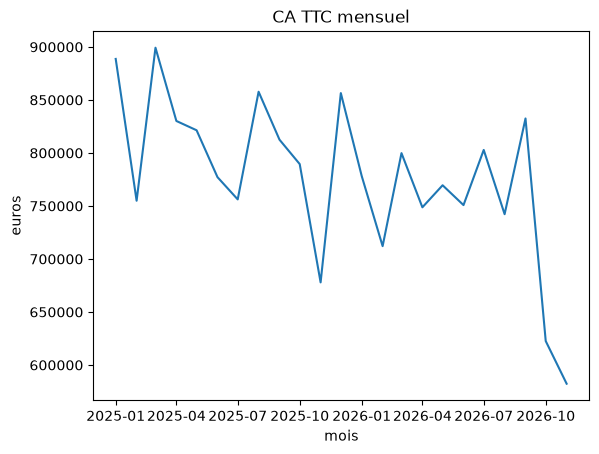

In [3]:
monthly = query("""
    select date_trunc('month', order_date)::date as mois,
           sum(net_amount_incl_vat) as ca_ttc
    from marts.fct_orders
    where is_revenue
    group by 1
    order by 1
""")
ax = monthly.plot(x="mois", y="ca_ttc", legend=False)
ax.set_title("CA TTC mensuel")
ax.set_ylabel("euros");

## Segment à la date de la commande et segment actuel

In [4]:
query("""
    select o.customer_segment_at_order as segment_commande,
           c.customer_segment as segment_actuel,
           count(*) as commandes
    from marts.fct_orders o
    join marts.dim_customers c using (customer_id)
    group by 1, 2
    order by 1, 2
""")

,segment_commande,segment_actuel,commandes
0,Premium,Premium,3119
1,Premium,VIP,667
2,Standard,Premium,2489
3,Standard,Standard,12901
4,Standard,VIP,986
5,VIP,VIP,748


## Prix au m² DVF

In [5]:
query("""
    select department_code, sale_category,
           count(*) as ventes,
           round(percentile_cont(0.5) within group
                 (order by price_per_m2)::numeric) as prix_m2_median
    from marts.fct_dvf_sales
    where is_reference_sale and not is_price_outlier
    group by 1, 2
    order by 1, 2
""")

,department_code,sale_category,ventes,prix_m2_median
0,33,Appartement,16428,3661.0
1,33,Maison,19532,3333.0
2,69,Appartement,28556,3738.0
3,69,Maison,8484,3597.0
4,75,Appartement,53841,9677.0
5,75,Maison,242,12394.0


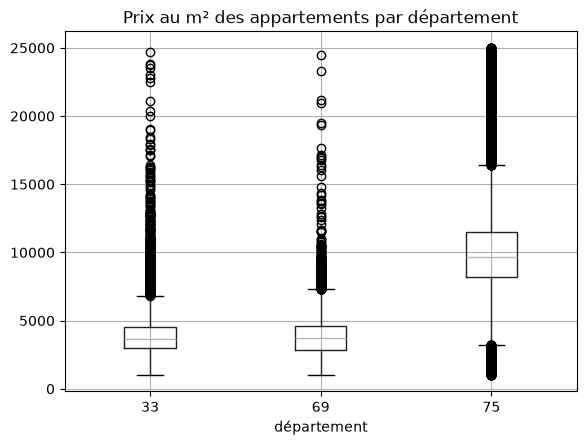

In [6]:
prices = query("""
    select department_code, price_per_m2
    from marts.fct_dvf_sales
    where is_reference_sale and not is_price_outlier
      and sale_category = 'Appartement'
""")
ax = prices.boxplot(column="price_per_m2", by="department_code")
ax.set_title("Prix au m² des appartements par département")
ax.figure.suptitle("")
ax.set_xlabel("département");